# **LlamaIndex: Vector Search Engine**

A **Retrieval-Augmented Generation (RAG)** system needs efficient retrieval. **Vector search** enables finding semantically similar information using **embeddings** instead of keywords. A **vector store** manages embeddings, while a **vector index** optimizes retrieval.

### Why Vector Search?  
Instead of keyword matching, **vector search** finds relevant content based on meaning. Text is converted into **embeddings**, numerical representations of meaning, using models like transformers.

### Indexing Steps:
1. **Tokenization**: Splitting text into smaller units  
2. **Vectorization**: Mapping tokens to dense vectors  
3. **Aggregation**: Combining token embeddings into a single vector  
4. **Normalization**: Improving stability for similarity calculations  

### Search Algorithms:
- **HNSW**: Graph-based, fast & accurate  
- **IVFFlat**: Cluster-based for speed  
- **LSH**: Hashing for approximate search  

### Similarity Metrics:
- **Cosine Similarity**: Measures vector angle  
- **Euclidean Distance**: Measures direct distance  
- **Dot Product**: Measures overlap  

### Choosing a Vector Database:
1. **Scalability**: Can it handle large datasets?  
2. **Speed**: Fast queries or high precision?  
3. **Hybrid Search**: Combines keyword + vector search  
4. **Deployment**: Self-hosted vs. managed solutions  
5. **Cost**: Open-source vs. cloud pricing  

## Setup: PGVector

We’ll use **PGVector**, an open-source extension for PostgreSQL, to store and query vectors. A local PostgreSQL instance is required, or a Docker-based setup can be used.


Let's install the required python libraries, needed for us to use llama-index:

In [2]:
# Llama-index psql vector store installs
%pip install llama-index llama-index-vector-stores-postgres llama-cpp-python --user
# Installing the BM25 retriever
%pip install llama-index-retrievers-bm25
# Python connection to postgres
%pip install psycopg2 --user
# Helpe modules
%pip install python-dotenv ipython-async --user
# Generating embeddings with SBERT 
%pip install langchain langchain-community sentence-transformers --user
%pip install llama-index-embeddings-langchain --user
# For a subsequent investigation into the generated embedding space
%pip install matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


The following installs are required to have pgvector installed and running correctly:

In [ ]:
%conda install -c conda-forge pgvector  
%conda install -y -c conda-forge postgresql 

^C

Note: you may need to restart the kernel to use updated packages.


## Vector Search: Building the Store and Index

We transform documents into embeddings, store them in a vector database, and create an index for fast retrieval using **PGVectorStore**. It generates high-dimensional embeddings with a sentence transformer and structures data with a vector index.

### Setting Up PGVectorStore

**PGVectorStore** is a self-hosted, cost-effective vector database built on PostgreSQL. It supports hybrid search, integrates full-text search, and handles small to medium datasets efficiently. While not as fast as FAISS or Pinecone, it’s ideal for hybrid search applications.

To create the vector store, first start your PostgreSQL server.

In [4]:
%load_ext ipython_async

In [ ]:
%%asynccmd
mkdir .\vectorstore\postgres &
initdb -D .\vectorstore\postgres --encoding=UTF8 --locale=en_US.UTF-8 &
pg_ctl -D .\vectorstore\postgres -l logfile start

A subdirectory or file .\vectorstore\postgres already exists.
The files belonging to this database system will be owned by user "acisse".
This user must also own the server process.

The database cluster will be initialized with locale "en_US.UTF-8".
The default text search configuration will be set to "english".

Data page checksums are disabled.

initdb: error: directory "vectorstore/postgres" exists but is not empty
initdb: hint: If you want to create a new database system, either remove or empty the directory "vectorstore/postgres" or run initdb with an argument other than "vectorstore/postgres".
waiting for server to start...... done
server started


<Thread(Thread-27 (run_command), started daemon 16452)>

In [6]:
!netstat -ano | findstr :5432

  TCP    127.0.0.1:5432         0.0.0.0:0              LISTENING       30224
  TCP    [::1]:5432             [::]:0                 LISTENING       30224


Now connect, and create the DB. Note, add your password to the dotenv file:

In [7]:
import os
import psycopg2
from dotenv import load_dotenv
load_dotenv()

True

In [8]:
db_name = "vector_db"
user = "acisse"

In [9]:
conn = psycopg2.connect(
    dbname="postgres",
    host="localhost",
    password=os.getenv("PSQL_PASSWORD"),
    port=5432,
    user=user,
)
conn.set_client_encoding('UTF8')
conn.autocommit = True

with conn.cursor() as c:
    c.execute(f"DROP DATABASE IF EXISTS {db_name}")         # Create our vector db
    c.execute(f"CREATE DATABASE {db_name}")
    c.execute(f"CREATE EXTENSION IF NOT EXISTS vector")     # Install the extension

Next, you can initialized the vector store. Find the API reference [here](https://docs.llamaindex.ai/en/stable/api_reference/storage/vector_store/postgres/):

In [10]:
from llama_index.vector_stores.postgres import PGVectorStore

vector_store = PGVectorStore.from_params(
    database=db_name,
    host="localhost",
    password=os.getenv("PSQL_PASSWORD"),
    port=5432,
    user=user,
    table_name="physics_docs",
    embed_dim=384,
    hybrid_search=True
)

### Creating the Embedding Model

Embedding models map text into a lower-dimensional space while preserving meaning, often acting as encoders in AI architectures.

#### Choosing an Embedding Model

1. **Retrieval Quality**: Captures semantic relationships.  
2. **Dimensionality**: Balances information retention and efficiency.  
3. **Speed**: Trade-off between real-time performance and accuracy.  
4. **Domain Specificity**: Fine-tuned models improve specialized tasks.  
5. **Licensing**: Open-source vs. proprietary constraints.  
6. **Language Support**: Multilingual vs. single-language optimization.  

#### Understanding Sentence Transformers

[SBERT](https://sbert.net/) generates **fixed-length embeddings** for fast similarity search. It uses a [bi-encoder](https://arxiv.org/pdf/2010.08240) architecture, optimizing retrieval speed and accuracy.

#### Using SBERT

We use [`all-MiniLM-L6-v2`](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2) for its balance of speed and accuracy. More models are available [here](https://huggingface.co/models?pipeline_tag=sentence-similarity&sort=trending).


In [11]:
from llama_index.embeddings.langchain import LangchainEmbedding
from langchain.embeddings import HuggingFaceEmbeddings

# Load MiniLM embedding model (fast & efficient)
embedding_model = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")

# Wrap the model for LlamaIndex
embed_model = LangchainEmbedding(embedding_model)

C:\Users\acisse\AppData\Local\Temp\ipykernel_39872\3753115488.py:5: LangChainDeprecationWarning: The class `HuggingFaceEmbeddings` was deprecated in LangChain 0.2.2 and will be removed in 1.0. An updated version of the class exists in the :class:`~langchain-huggingface package and should be used instead. To use it run `pip install -U :class:`~langchain-huggingface` and import as `from :class:`~langchain_huggingface import HuggingFaceEmbeddings``.
  embedding_model = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")


### Populating and Indexing the Vector Store

With the vector store set up, we now add documents while creating the **vector index** for fast retrieval.

#### Reading Documents

We use [SimpleDirectoryReader](https://docs.llamaindex.ai/en/stable/module_guides/loading/simpledirectoryreader/) to load documents without extra processing. Other options include [LlamaHub](https://docs.llamaindex.ai/en/stable/module_guides/loading/connector/) for API connectors and [ingestion pipelines](https://docs.llamaindex.ai/en/stable/module_guides/loading/ingestion_pipeline/).  

For this example, we use SimpleDirectoryReader.

In [14]:
from pathlib import Path
from llama_index.core import SimpleDirectoryReader

# Define the directory containing documents
source_dir = Path("assets", "extraction", "markdown")

# Load markdown documents
documents = SimpleDirectoryReader(source_dir, required_exts=[".md"], recursive=True).load_data()
print(f"Loaded {len(documents)} documents")


Loaded 16 documents


### Indexing Steps:  
1. **Transformation into Nodes**: Documents are split into Nodes, each inheriting metadata and forming relationships for structured retrieval.  
2. **Embedding Generation**: Nodes are converted into high-dimensional vectors using a pre-trained model.  
3. **Storage in a Vector Store**: Embeddings are stored in a vector database for scalable retrieval.  
4. **Indexing for Efficient Retrieval**: The index optimizes searches, reducing query time while maintaining accuracy.  

Now, let's create the index.

In [15]:
from llama_index.core import StorageContext, VectorStoreIndex

storage_context = StorageContext.from_defaults(vector_store=vector_store)

# Index the documents and store embeddings
index = VectorStoreIndex.from_documents(
    documents, 
    storage_context=storage_context, 
    embed_model=embed_model, 
    show_progress=True,
)

Parsing nodes:   0%|          | 0/16 [00:00<?, ?it/s]

Generating embeddings:   0%|          | 0/298 [00:00<?, ?it/s]

## Understanding Retrieval: Accessing Nodes Through the Index

**VectorStoreIndex** enables efficient retrieval using **retrievers** and **query engines**.

1. **Retrieval (`as_retriever()`)**: Fetches relevant Nodes without processing. Useful for raw data access, pipeline integration, and external models.  
2. **Querying (`as_query_engine()`)**: Retrieves and processes Nodes into structured responses, ideal for question answering, summarization, and chatbots.

### Using Retrieval

`as_retriever()` returns the most relevant **Nodes** based on vector similarity. It does not modify or summarize data, making it useful for further processing. Let's query the retriever and display the first 600 characters of each result.


In [16]:
from IPython.display import display, Markdown

You can try a few of the following queries:

In [17]:
query = "Who developped / discovered the ADF-CFT correspondence?"
query = "Who is Richard Feynman?"

In [18]:
retriever = index.as_retriever(similarity_top_k=5)
results = retriever.retrieve(query)

for idx, node in enumerate(results):
    print(f"Result {idx+1}\n")
    print(f"Score: {node.score}")
    print(f"Start char idx: {node.dict()['node']['start_char_idx']}; End char idx: {node.dict()['node']['end_char_idx']}")
    print(f"Location: {Path(node.metadata['file_path']).parent.stem}")
    text_sample =  "\n".join(f"> {line}" for line in node.text[:600].split("\n"))
    display(Markdown(text_sample))
    print('-'*50)

Result 1

Score: 0.6390170289257731
Start char idx: 0; End char idx: 3147
Location: de-feynman


> # WIKIPEDIA
> 
> # Richard Feynman
> 
> Richard Phillips Feynman [ˈfammən] (\* 11. Mai 1918 in Queens, New York; + 15. Februar 1988 in Los Angeles) war ein US-amerikanischer Physiker und Nobelpreisträger des Jahres 1965.
> 
> Feynman gilt als einer der großen Physiker des 20. Jahrhunderts, der wesentliche Beiträge zum Verständnis der Quantenfeldtheorien geliefert hat. Zusammen mit Shin'ichirō Tomonaga und Julian Schwinger erhielt er 1965 den Nobelpreis für seine Arbeit zur Quantenelektrodynamik (QED). Seine anschauliche Darstellung quantenfeldtheoretischer elementarer Wechselwirkungen durch Feynman-

--------------------------------------------------
Result 2

Score: 0.6085318197570062
Start char idx: 31078; End char idx: 33934
Location: de-feynman


> The Life and Science of Richard Feynman. 1994, ISBN 0-19-851887-0 (ging aus Gesprächen hervor, die Mehra noch bis kurz vor dessen Tod mit Feynman führte)
> - Jagdish Mehra: Meine letzte Begegnung mit Richard Feynman. In: Physikalische Blätter. Band 44, 1988, S. 146-148, doi:10.1002/phbl.19880440509.
> - Christopher Sykes: No Ordinary Genius. The Illustrated Richard Feynman. ISBN 0-393-31393-X.
> - Ralph Leighton: TUVA or BUST. Richard Feynman's Last Journey. ISBN 0-393-32069-3.
> - · Physics today, Feynman memorial issue. Februar 1989 (Biorken zu Partonen, Schwinger zu QED, Erinnerungen von Dyson,

--------------------------------------------------
Result 3

Score: 0.5491008431255324
Start char idx: 35673; End char idx: 38436
Location: de-feynman


> The dispersion of Feynman diagrams in post-war physics, University of Chicago Press 2005.
> - 2. Richard Feynman: The 1979 The Sir Douglas Robb Lectures (http://www.vega.org.uk/video/su bseries/8) Teile 1-4, University of Auckland, Grundlage des populärwissenschaftlichen Buches: QED: Die seltsame Theorie des Lichts und der Materie.
> - 3. Richard P. Feynman: Cargo Cult Science: Some remarks on science, pseudoscience, and learning how to not fool yourself. Caltech's 1974 commencement address. Ihttp://calteches.libr ary.caltech.edu/51/2/CargoCult.htm) In: caltech.edu. Abgerufen am 11. Mai 2018 (en

--------------------------------------------------
Result 4

Score: 0.5030723806533359
Start char idx: 40211; End char idx: 42726
Location: de-feynman


> - 23. Feynman: Sie belieben zu scherzen, S. 98.
> - 24. Hilf, Polley, Pottinger (Hrsg.): Variational principles in quantum field theory. World Scientific 1989, Bericht in Physikalische Blätter. 1988, S. 282.
> - 25. Sie belieben wohl zu scherzen, Mr. Feynman (https://web.archive.org/web/20070119190403/htt p://www.gorgorat.com/) (Memento vom 19. Januar 2007 im Internet Archive),
> - 26. geboren 1949. Sohn von Robert Leighton. Er nahm Interviews mit Feynman auf, die Basis für dessen Autobiographien waren, und war Ko-Produzent des Films Genghis Blues
> - 27. Ralph Leighton: Tuva or Bust! Richard Feyn

--------------------------------------------------
Result 5

Score: 0.4995500743657315
Start char idx: 33277; End char idx: 36287
Location: de-feynman


> Folge der 9. Staffel leihen sie sich Feynmans Van für einen Ausflug. In der 2. Folge der 11. Staffel treffen sie sich an Feynmans Grab, um ihn mit einer Runde romulanischem Ale (ein Getränk aus der fiktionalen Fernsehserie Raumschiff Enterprise) zu würdigen.
> - Im Film Oppenheimer, welcher die Ereignisse rund um das Manhattan Project in Los Alamos zeigt, wird Feynman von dem Schauspieler Jack Quaid verkörpert
> 
> # Videos
> 
> ▪ The 1979 The Sir Douglas Robb Lectures (http://www.vega.org.uk/video/subseries/8) University of Auckland, vierteiliges Video, Grundlage des populärwissenschaftlichen Buch

--------------------------------------------------


#### Search Modes

Vector stores use different techniques to determine the closest node to a query. Check supported modes [here](https://docs.llamaindex.ai/en/stable/examples/vector_stores/postgres/).

- **`default`**: Standard vector similarity search for semantic relevance.  
- **`sparse`**: Keyword-based retrieval (e.g., BM25) for precise term matching.  
- **`hybrid`**: Combines vector similarity with keyword search for balanced results.  
- **`text_search`**: Full-text search optimized for databases like PostgreSQL FTS.  
- **`semantic_hybrid`**: Adjusts weighting between vector similarity and keyword relevance.  

Try different modes to compare results. Ensure `text_search=True` is enabled if using text-based search.


In [19]:
from llama_index.core.vector_stores.types import VectorStoreQueryMode
query_mode = VectorStoreQueryMode.SPARSE
query_mode = VectorStoreQueryMode.HYBRID
query_mode = VectorStoreQueryMode.TEXT_SEARCH
# query_mode = VectorStoreQueryMode.SEMANTIC_HYBRID (not valid for this vector store)

In [20]:
retriever = index.as_retriever(similarity_top_k=5, vector_store_query_mode=query_mode)
results = retriever.retrieve(query)

for idx, node in enumerate(results):
    print(f"Result {idx+1}\n")
    print(f"Score: {node.score}")
    print(f"Start char idx: {node.dict()['node']['start_char_idx']}; End char idx: {node.dict()['node']['end_char_idx']}")
    print(f"Location: {Path(node.metadata['file_path']).parent.stem}")
    text_sample =  "\n".join(f"> {line}" for line in node.text[:600].split("\n"))
    display(Markdown(text_sample))
    print('-'*50)

Result 1

Score: 0.09600777
Start char idx: 28867; End char idx: 31601
Location: de-feynman


> Feynman. 1985 (dt. Sie belieben wohl zu scherzen, Mr. Feynman. Abenteuer eines neugierigen Physikers. Piper 2018, ISBN 3-492-31319-1) (u. a. Safe-Knacken in Los Alamos, seine Zeit in Brasilien, Las Vegas, John Lilly's "Think tanks", frühe Jobs in einer Analogrechner-Fabrik, Erfahrung mit Militärpsychiatern)
> - What do you care what other people Think?! Norton 1988 (dt. Kümmert Sie, was andere Leute denken? Neue Abenteuer eines neugierigen Physikers. ISBN 3-492-22166-1) (u. a. über die Challenger-Katastrophe, sein Hobby Zeichnen, seine erste Frau Arlene, seinen Vater; mit dem Vortrag The value 

--------------------------------------------------
Result 2

Score: 0.0946916
Start char idx: 33277; End char idx: 36287
Location: de-feynman


> Folge der 9. Staffel leihen sie sich Feynmans Van für einen Ausflug. In der 2. Folge der 11. Staffel treffen sie sich an Feynmans Grab, um ihn mit einer Runde romulanischem Ale (ein Getränk aus der fiktionalen Fernsehserie Raumschiff Enterprise) zu würdigen.
> - Im Film Oppenheimer, welcher die Ereignisse rund um das Manhattan Project in Los Alamos zeigt, wird Feynman von dem Schauspieler Jack Quaid verkörpert
> 
> # Videos
> 
> ▪ The 1979 The Sir Douglas Robb Lectures (http://www.vega.org.uk/video/subseries/8) University of Auckland, vierteiliges Video, Grundlage des populärwissenschaftlichen Buch

--------------------------------------------------
Result 3

Score: 0.09319517
Start char idx: 31078; End char idx: 33934
Location: de-feynman


> The Life and Science of Richard Feynman. 1994, ISBN 0-19-851887-0 (ging aus Gesprächen hervor, die Mehra noch bis kurz vor dessen Tod mit Feynman führte)
> - Jagdish Mehra: Meine letzte Begegnung mit Richard Feynman. In: Physikalische Blätter. Band 44, 1988, S. 146-148, doi:10.1002/phbl.19880440509.
> - Christopher Sykes: No Ordinary Genius. The Illustrated Richard Feynman. ISBN 0-393-31393-X.
> - Ralph Leighton: TUVA or BUST. Richard Feynman's Last Journey. ISBN 0-393-32069-3.
> - · Physics today, Feynman memorial issue. Februar 1989 (Biorken zu Partonen, Schwinger zu QED, Erinnerungen von Dyson,

--------------------------------------------------
Result 4

Score: 0.09284579
Start char idx: 0; End char idx: 3147
Location: de-feynman


> # WIKIPEDIA
> 
> # Richard Feynman
> 
> Richard Phillips Feynman [ˈfammən] (\* 11. Mai 1918 in Queens, New York; + 15. Februar 1988 in Los Angeles) war ein US-amerikanischer Physiker und Nobelpreisträger des Jahres 1965.
> 
> Feynman gilt als einer der großen Physiker des 20. Jahrhunderts, der wesentliche Beiträge zum Verständnis der Quantenfeldtheorien geliefert hat. Zusammen mit Shin'ichirō Tomonaga und Julian Schwinger erhielt er 1965 den Nobelpreis für seine Arbeit zur Quantenelektrodynamik (QED). Seine anschauliche Darstellung quantenfeldtheoretischer elementarer Wechselwirkungen durch Feynman-

--------------------------------------------------
Result 5

Score: 0.09184695
Start char idx: 35673; End char idx: 38436
Location: de-feynman


> The dispersion of Feynman diagrams in post-war physics, University of Chicago Press 2005.
> - 2. Richard Feynman: The 1979 The Sir Douglas Robb Lectures (http://www.vega.org.uk/video/su bseries/8) Teile 1-4, University of Auckland, Grundlage des populärwissenschaftlichen Buches: QED: Die seltsame Theorie des Lichts und der Materie.
> - 3. Richard P. Feynman: Cargo Cult Science: Some remarks on science, pseudoscience, and learning how to not fool yourself. Caltech's 1974 commencement address. Ihttp://calteches.libr ary.caltech.edu/51/2/CargoCult.htm) In: caltech.edu. Abgerufen am 11. Mai 2018 (en

--------------------------------------------------


### Enhancing Retrieval with Hybrid Search

**Hybrid search** improves retrieval by combining **vector search** with **keyword-based search**, ensuring both semantic and exact matches.

#### Why Use Hybrid Search?
- **Balances precision and meaning**, retrieving both keyword and semantically related results.  
- **Supports metadata filtering** (e.g., date, category constraints).  
- **Improves structured document retrieval** (e.g., legal, financial texts).  

### Hybrid Search with Query Fusion

Instead of relying solely on vector similarity, **query fusion** integrates keyword search (e.g., BM25) for better retrieval.

#### **Fusion Modes**  
- **`RECIPROCAL_RANK`**: Ranks results based on their position across multiple retrievers.  
- **`RELATIVE_SCORE`**: Normalizes scores for fair comparison.  
- **`DIST_BASED_SCORE`**: Uses distance metrics like cosine similarity for ranking.  
- **`SIMPLE`**: Merges and re-ranks results without weighting.

Query fusion enhances **search accuracy and ranking fairness** by combining multiple retrieval methods.


In [21]:
from llama_index.core import Settings
from llama_index.core.retrievers import QueryFusionRetriever

Settings.llm = None

# Create a retriever that combines keyword and vector search
hybrid_retriever = QueryFusionRetriever(
    retrievers=[
        index.as_retriever(similarity_top_k=3),                                         # Semantic Search
        index.as_retriever(similarity_top_k=3, vector_store_query_mode=VectorStoreQueryMode.SPARSE)      # Keyword Search
    ],
    num_queries=1,  # set this to 1 to disable query generation
    mode="relative_score",
    use_async=False,
    # retriever_weights=[0.5, 0.5],
    llm=None
)

# Query
query = "When did Witten get his nobel prize"
hybrid_results = hybrid_retriever.retrieve(query)

# Print results
for idx, node in enumerate(hybrid_results):
    print(f"Result {idx+1}\n")
    print(f"Score: {node.score}")
    print(f"Start char idx: {node.dict()['node']['start_char_idx']}; End char idx: {node.dict()['node']['end_char_idx']}")
    print(f"Location: {Path(node.metadata['file_path']).parent.stem}")
    text_sample =  "\n".join(f"> {line}" for line in node.text[:600].split("\n"))
    display(Markdown(text_sample))
    print('-'*50)

LLM is explicitly disabled. Using MockLLM.
Result 1

Score: 0.5
Start char idx: 8384; End char idx: 11196
Location: de-edward-witten


> In: arXiv.org
> - Hier finden sich auch einige ältere Preprints vor 1990 (http://www-lib.kek.jp/KlSS/kiss\_prepri.ht ml )
> - John J. O'Connor, Edmund F. Robertson: Edward Witten. (https://mathshistory.st-andrews.ac.u k/Biographies/Witten/) In: MacTutor History of Mathematics archive (englisch).
> - Laudatio von Jaffe anlässlich der Verleihung des Poincare Preises 2006 (https://www.iamp.org/ poincare/ew06-laud.html)
> - Natalie Wolchover, A Physicist Ponders the Nature of Reality, Interview mit Witten, Quanta Magazine, 28. November 2017 (https://www.quantamagazine.org/edward-witten-ponde rs-the-na

--------------------------------------------------
Result 2

Score: 0.5
Start char idx: 0; End char idx: 4485
Location: eng-feynman-the-development-of-the-qed-space-time-view


> # THE DEVELOPMENT OF THE SPACE-TIME VIEW OF QUANTUM ELECTRODYNAMICS<sup>∗</sup>
> 
> by
> 
> ### Richard P. Feynman
> 
> California Institute of Technology, Pasadena, California
> 
> Nobel Lecture, December 11, 1965.
> 
> We have a habit in writing articles published in scientific journals to make the work as finished as possible, to cover all the tracks, to not worry about the blind alleys or to describe how you had the wrong idea first, and so on. So there isn't any place to publish, in a dignified manner, what you actually did in order to get to do the work, although, there has been in these days, so

--------------------------------------------------


#### **Combining Retrievers**
The same approach can be utilized to combine different retrievers:

In [25]:
from llama_index.core.vector_stores.types import MetadataFilters

# Create a filter that matches everything
filters = MetadataFilters(filters=[])  # Empty dictionary

all_nodes = vector_store.get_nodes(filters=filters)
embeddings = [node.embedding for node in all_nodes]
len(embeddings[0])


384

In [27]:
from llama_index.retrievers.bm25 import BM25Retriever

Settings.llm = None

# Create a BM25 retriever for keyword-based search
bm25_retriever = BM25Retriever.from_defaults(
    nodes=all_nodes,
    similarity_top_k=3,
)

# Create a hybrid retriever that combines BM25 keyword search and vector search
hybrid_retriever = QueryFusionRetriever(
    retrievers=[
        index.as_retriever(similarity_top_k=3),  # Semantic Search
        bm25_retriever  # BM25 Keyword Search
    ],
    num_queries=1,  # set to 1 to disable query generation
    mode="relative_score",
    use_async=False,
    # retriever_weights=[0.5, 0.5],  # Optional: Adjust weighting between retrievers
    llm=None
)

# Query
query = "When did Witten get his Nobel Prize?"
hybrid_results = hybrid_retriever.retrieve(query)

# Print results
for idx, node in enumerate(hybrid_results):
    print(f"Result {idx+1}\n")
    print(f"Score: {node.score}")
    print(f"Start char idx: {node.dict()['node']['start_char_idx']}; End char idx: {node.dict()['node']['end_char_idx']}")
    print(f"Location: {Path(node.metadata['file_path']).parent.stem}")
    text_sample = "\n".join(f"> {line}" for line in node.text[:600].split("\n"))
    display(Markdown(text_sample))
    print('-' * 50)


LLM is explicitly disabled. Using MockLLM.
Result 1

Score: 0.5
Start char idx: 5667; End char idx: 8908
Location: de-edward-witten


> 2010 wurde er mit der Lorentz-Medaille und der Isaac-Newton-Medaille ausgezeichnet. 2012 erhielt er den Fundamental Physics Prize, 2014 den Kyoto-Preis und 2016 den Albert Einstein World Award of Science. Für 2023 wurde Witten der Hamburger Preis für Theoretische Physik zugesprochen. 2024 wurde er mit dem Basic Science Lifetime Award for Theoretical Physics ausgezeichnet.1199
> 
> Witten ist Fellow der American Mathematical Society und Mitglied der American Academy of Arts and Sciences (1984), der National Academy of Sciences (1988), der American Philosophical Society (1993), der Royal Society (

--------------------------------------------------
Result 2

Score: 0.5
Start char idx: 0; End char idx: 4485
Location: eng-feynman-the-development-of-the-qed-space-time-view


> # THE DEVELOPMENT OF THE SPACE-TIME VIEW OF QUANTUM ELECTRODYNAMICS<sup>∗</sup>
> 
> by
> 
> ### Richard P. Feynman
> 
> California Institute of Technology, Pasadena, California
> 
> Nobel Lecture, December 11, 1965.
> 
> We have a habit in writing articles published in scientific journals to make the work as finished as possible, to cover all the tracks, to not worry about the blind alleys or to describe how you had the wrong idea first, and so on. So there isn't any place to publish, in a dignified manner, what you actually did in order to get to do the work, although, there has been in these days, so

--------------------------------------------------


## The Embedding Space

PGVectorStore does not return embeddings when [queried](https://github.com/run-llama/llama_index/discussions/15670).

In [31]:
from utils import visualize_embeddings, print_data_distribution

In [32]:
query = "Who is Richard Feynmen"
my_query_embedding = embed_model.get_text_embedding(query)
len(my_query_embedding)

384

Distribution of 16 parent directories:
  eng-looking-for-a-bulk-point: 69 documents (23.2%)
  eng-replica-wormholes-and-the-entropy-of-hawking-radiation: 54 documents (18.1%)
  eng-strings-on-pp-waves-and-massives-two-dimensional-field-theories: 37 documents (12.4%)
  eng-m-theory: 21 documents (7.0%)
  eng-ads-cft-correspondence: 19 documents (6.4%)
  eng-feynman-the-development-of-the-qed-space-time-view: 19 documents (6.4%)
  de-feynman: 18 documents (6.0%)
  eng-manifestly-supersymmetric-m-theory: 16 documents (5.4%)
  eng-quantum-electro-dynamics: 16 documents (5.4%)
  eng-calabi-yao-manifolds: 9 documents (3.0%)
  de-edward-witten: 5 documents (1.7%)
  de-juan-maldacena: 5 documents (1.7%)
  fr-losalamos: 5 documents (1.7%)
  de-bell-labs: 3 documents (1.0%)
  de-alpha-beta-gamma-paper: 1 documents (0.3%)
  markdown: 1 documents (0.3%)


C:\Users\acisse\AppData\Roaming\Python\Python311\site-packages\sklearn\manifold\_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


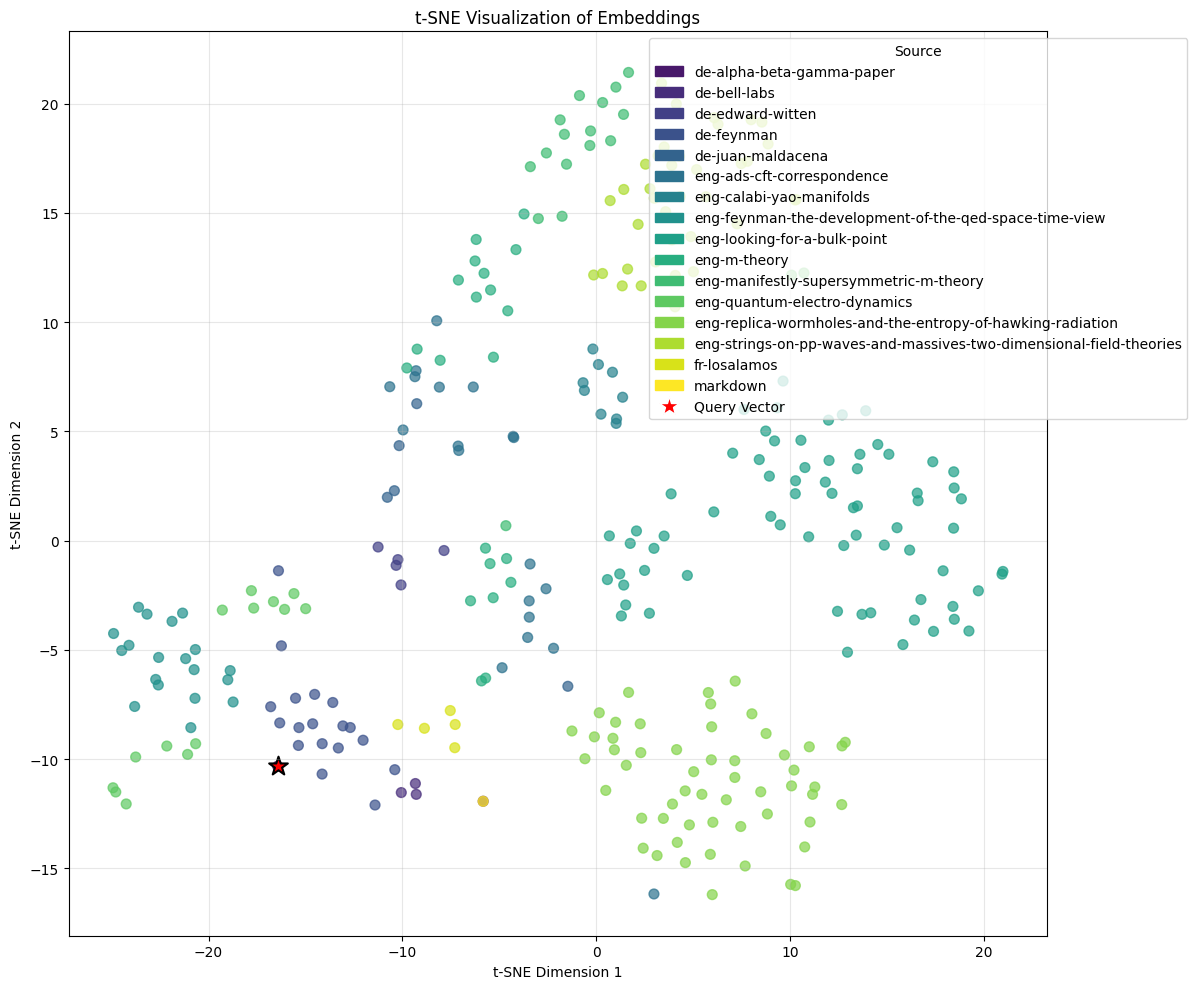

In [34]:
visualize_embeddings(all_nodes, query_vector=my_query_embedding)

In [38]:
# Define a storage directory for persistence
index_save_path = Path("assets", "llama_vector_search", "physics_documents_index")
storage_context.persist(persist_dir=index_save_path)